## Phase 5 : Data Visualisation et Insights Métier

L'objectif de cette analyse visuelle est de répondre à deux problématiques clés de la chaîne d'approvisionnement d'Olist :
1. **L'impact logistique :** Quelle est la corrélation entre le temps d'acheminement et la satisfaction client ?
2. **L'empreinte géographique :** Quelles régions brésiliennes souffrent des plus fortes frictions logistiques ?

Nous utilisons `matplotlib` et `seaborn` pour générer des visualisations agrégées à partir de notre "Gold Table".

C:\Users\LBC\AppData\Local\Temp\ipykernel_6732\2603523055.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax1 = sns.barplot(


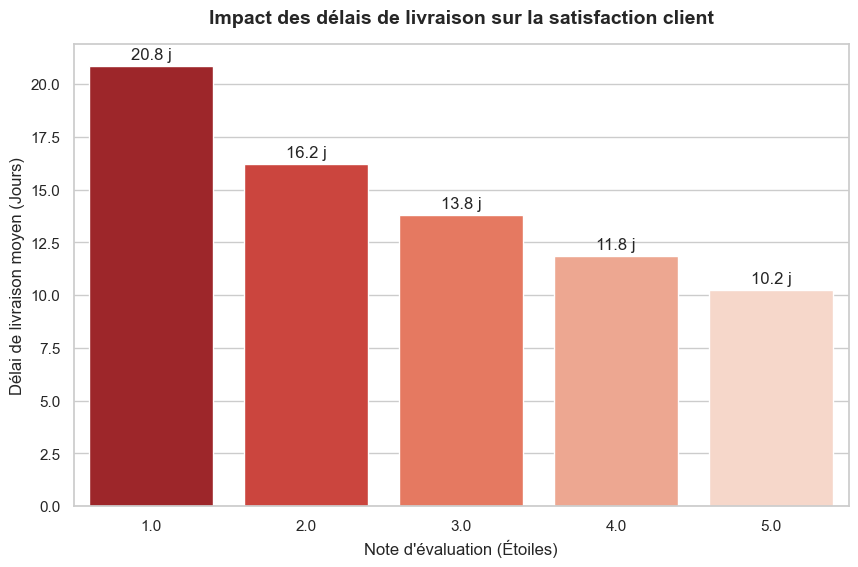

C:\Users\LBC\AppData\Local\Temp\ipykernel_6732\2603523055.py:44: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax2 = sns.barplot(


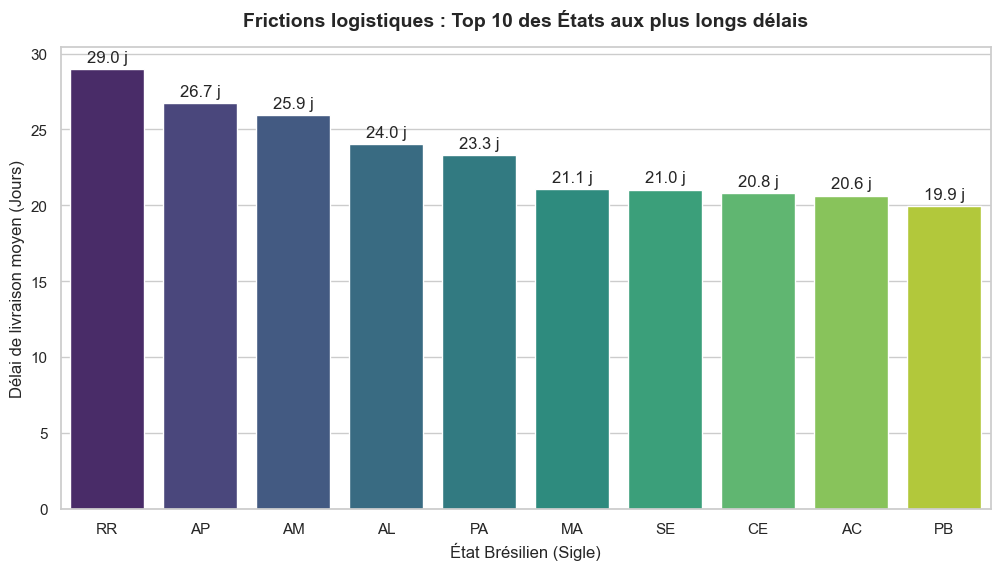

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Création du dossier pour stocker les images (s'il n'existe pas déjà)
output_dir = Path.cwd() / "assets"
output_dir.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
df_master = pd.read_csv("data/olist_master_dataset.csv")

# ==========================================
# GRAPHIQUE 1 : Impact Délai vs Satisfaction
# ==========================================
plt.figure(figsize=(10, 6))
ax1 = sns.barplot(
    data=df_master, 
    x='review_score', 
    y='delivery_time_days', 
    estimator='mean',
    errorbar=None, 
    palette='Reds_r'
)

plt.title("Impact des délais de livraison sur la satisfaction client", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Note d'évaluation (Étoiles)", fontsize=12)
plt.ylabel("Délai de livraison moyen (Jours)", fontsize=12)

for i in ax1.containers:
    ax1.bar_label(i, fmt='%.1f j', padding=3)

# Sauvegarde de l'image (Haute résolution)
plt.savefig(output_dir / 'impact_delai_note.png', dpi=300, bbox_inches='tight')
plt.show()

# ==========================================
# GRAPHIQUE 2 : Top 10 des pires délais géographiques
# ==========================================
plt.figure(figsize=(12, 6))

state_delays = df_master.groupby('customer_state')['delivery_time_days'].mean().sort_values(ascending=False).head(10).reset_index()

ax2 = sns.barplot(
    data=state_delays, 
    x='customer_state', 
    y='delivery_time_days', 
    palette='viridis'
)

plt.title("Frictions logistiques : Top 10 des États aux plus longs délais", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("État Brésilien (Sigle)", fontsize=12)
plt.ylabel("Délai de livraison moyen (Jours)", fontsize=12)

for i in ax2.containers:
    ax2.bar_label(i, fmt='%.1f j', padding=3)

# Sauvegarde de l'image (Haute résolution)
plt.savefig(output_dir / 'top_10_etats_delais.png', dpi=300, bbox_inches='tight')
plt.show()

### 💡 Conclusions Stratégiques (Business Insights)

1. **La rapidité est la clé de la rétention :** Le premier graphique démontre une corrélation inversement proportionnelle parfaite. Les clients attribuant la note minimale (1 étoile) ont subi des délais dépassant les 20 jours en moyenne, tandis que les promoteurs (5 étoiles) sont livrés en moins de 11 jours.
2. **Des disparités régionales critiques :** Le second graphique isole les États (comme Roraima - RR ou Amapá - AP) où les délais moyens explosent au-delà des 25 jours. Ces zones géographiques nécessitent l'ouverture de nouveaux centres de distribution relais pour désengorger la chaîne de transport.